In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [36]:
from allensdk.core.mouse_connectivity_cache import MouseConnectivityCache
import matplotlib.pyplot as plt
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *

In [37]:
prefix = '/mnt/staging/'
figure_config_root = str(PREPARES / "config") + "/"
palatte_dict = load_pickle(figure_config_root+'palatte_dict')

In [38]:
from pathlib import Path


In [39]:
from allensdk.core.mouse_connectivity_cache import MouseConnectivityCache

# The manifest file is a simple JSON file that keeps track of all of
# the data that has already been downloaded onto the hard drives.
# If you supply a relative path, it is assumed to be relative to your
# current working directory.
result_path = str(PREPARES / "allen-connectivity-atlas/NEW/sim1-cre-S1")
output_dir = result_path
mcc = MouseConnectivityCache(manifest_file=Path(output_dir) / 'manifest.json',resolution=10)

# open up a list of all of the experiments
all_experiments = mcc.get_experiments(dataframe=True)
print("%d total experiments" % len(all_experiments))

# take a look at what we know about an experiment with a primary motor injection
all_experiments.loc[114290938]

2992 total experiments


gender                                                         M
injection_structures                                       [345]
injection_volume                                        0.368922
injection_x                                                 4530
injection_y                                                 2470
injection_z                                                 8980
product_id                                                     5
specimen_name                                           378-1165
strain                                                  C57BL/6J
structure_abbrev                                           SSp-m
structure_id                                                 345
structure_name                 Primary somatosensory area, mouth
transgenic_line                                             None
transgenic_line_id                                           NaN
id                                                     114290938
primary_injection_structu

In [40]:
S1_experiment_ids = {
    "VISrl": 297712045,
    "SSp-m":297985755, 
    "SSp-n": 297713365,
    "SSp-ul":297951732, 
    "SSp-ll": 297714071,
    "SSp-bfd": 298760261
}

In [41]:
dict_ind = {}
dict_ind_info = {}
dict_pd = {}
dict_pd_info = {}
for key in S1_experiment_ids:
    experiment_id = S1_experiment_ids[key]
    # injection density: number of projecting pixels in injection site / voxel volume
    ind, ind_info = mcc.get_injection_density(experiment_id) 
    dict_ind[key] = ind
    dict_ind_info[key] = ind_info
    # projection density: number of projecting pixels / voxel volume
    pd, pd_info = mcc.get_projection_density(experiment_id)
    dict_pd[key]=pd
    dict_pd_info[key]=pd_info
    

(1200.0, 160.0)

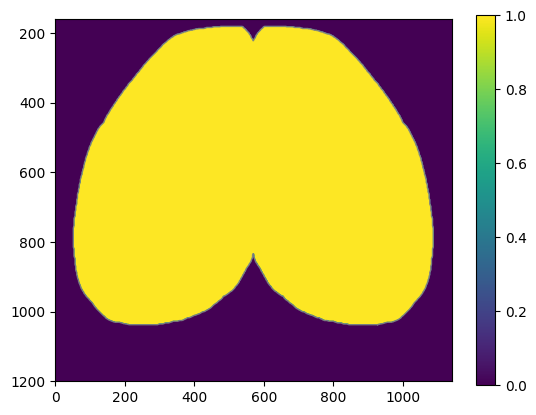

In [42]:
# in addition to the annotation volume, you can get binary masks for individual structures
# in this case, we'll get one for the isocortex
cortex_mask, cm_info = mcc.get_structure_mask(315)

cortex_mask_mip = cortex_mask.max(axis=1)

from skimage import measure
brain_contours = measure.find_contours(cortex_mask_mip>0.5, level=0.5)

    
plt.imshow(cortex_mask_mip)
plt.colorbar()
for contour in brain_contours:
    plt.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=0.9)
# plt.xlim([20,436])
plt.ylim([1200,160])

In [43]:
dict_coord={}
dict_S1_contour = {}
from scipy.ndimage import center_of_mass
for key in S1_experiment_ids:
    dict_coord[key] = center_of_mass(dict_ind[key].max(axis=1))
    S1_contours = measure.find_contours(dict_ind[key].max(axis=1)>0.5, level=0.5)
    dict_S1_contour[key] = S1_contours

# Make figure

In [44]:
from matplotlib.colors import LinearSegmentedColormap

from matplotlib.colors import LinearSegmentedColormap, to_rgb

def make_dynamic_cmap(hex_color, name):
    base_rgb = to_rgb(hex_color)
    
    # Add a middle point (scaled up to boost intensity)
    # boosted = tuple(min(1, c * 2) for c in base_rgb)
    boost = 2
    boosted = tuple(min(1.0, c * boost + 0.2 * (1 - c)) for c in base_rgb)
    return LinearSegmentedColormap.from_list(name, ['black', boosted, 'white'])


cmap_dict = {key: make_dynamic_cmap(color, key) for key, color in palatte_dict.items()}


In [45]:
dict_scaling_factor= {
    "VISrl": 1,
    "SSp-m": 1,
    "SSp-n": 1,
    "SSp-ul": 1,
    "SSp-ll": 1,
    "SSp-bfd": 1
                     }

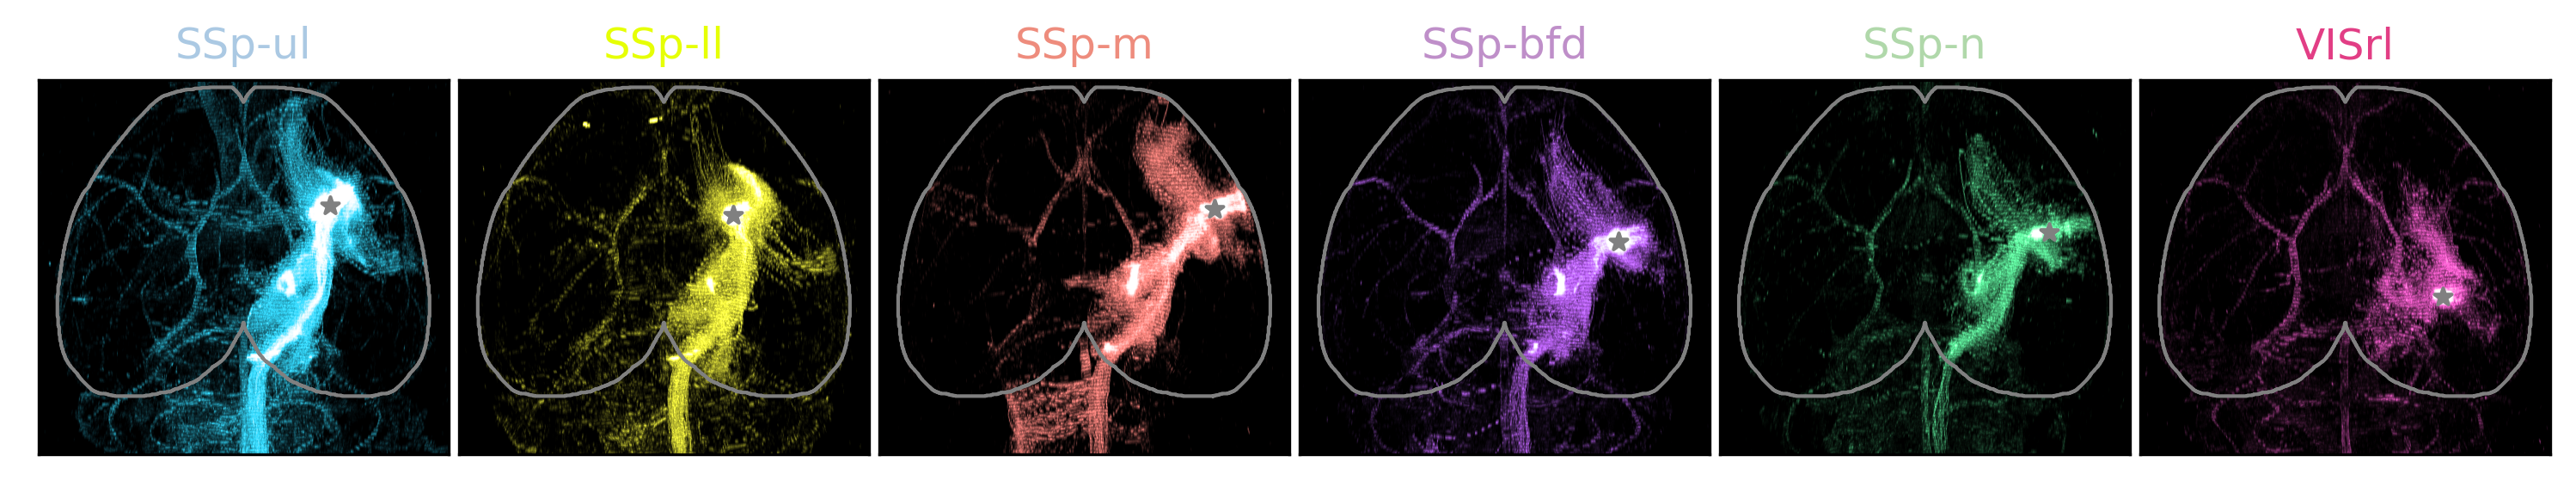

In [48]:
from matplotlib import colors
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)


y_offset = 20;x_offset=20;y_gap=1;x_gap=0;x_width=6

x_start = x_offset
for i_ax in range(6):
    exec("ax{} = fig.add_subplot(gs[y_offset:y_offset+7,x_start:x_start+7])".format(i_ax))
    x_start = x_start+7+x_gap
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    


bdp_short_dict = {'LFP':'SSp-ul','LHP':'SSp-ll','LM':'SSp-m','LW':'SSp-bfd',
                  'LN':'SSp-n','LV':'VISrl'}

dict_bdp_w_order = {'SSp-bfd':0,'SSp-ll':1,'SSp-m':2,'SSp-n':3,'SSp-ul':4,'VISrl':5}

################################################
for i_bdp,bdp in enumerate(['SSp-ul','SSp-ll','SSp-m','SSp-bfd','SSp-n','VISrl']):
    ind_here = dict_bdp_w_order[bdp]
    # pd_mip = arr[:,:,:,ind_here].max(axis=1)
    pd_mip = dict_pd[bdp].max(axis=1)
    
    key = next((k for k, v in bdp_short_dict.items() if v == bdp), None)
    exec("ax{}.imshow(pd_mip*dict_scaling_factor[bdp],cmap=cmap_dict[key.replace('L','R')],vmin=0,vmax=1)".format(i_bdp))
    exec("ax{}.set_title(bdp,color=palatte_dict[key])".format(i_bdp))

    for contour in brain_contours:
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=1)".format(i_bdp))
    exec("ax{}.scatter(dict_coord[bdp][1],dict_coord[bdp][0],marker='*', s=25, c='gray', zorder=2)".format(i_bdp))

        
for i_key in range(6):    
    exec("ax{}.set_ylim([1200,160])".format(i_key))
    
plt.savefig('figS5-SIM1-cre-S1-seeded-allen-connectivity-atlas-MIP.svg',format='svg',dpi=300)

# Tlx3-cre

In [49]:
from pathlib import Path


In [50]:
from allensdk.core.mouse_connectivity_cache import MouseConnectivityCache

# The manifest file is a simple JSON file that keeps track of all of
# the data that has already been downloaded onto the hard drives.
# If you supply a relative path, it is assumed to be relative to your
# current working directory.
result_path = str(PREPARES / "allen-connectivity-atlas/NEW/tlx3-cre-S1")
output_dir = result_path
mcc = MouseConnectivityCache(manifest_file=Path(output_dir) / 'manifest.json',resolution=10)

# open up a list of all of the experiments
all_experiments = mcc.get_experiments(dataframe=True)
print("%d total experiments" % len(all_experiments))

# take a look at what we know about an experiment with a primary motor injection
# all_experiments.loc[114290938]

2992 total experiments


In [51]:
S1_experiment_ids = {
'SSp-n': 288170549,
'SSp-bfd': 297654263,
'SSp-ll': 296052839,
'SSp-m': 303614706,
'SSp-ul': 303615412,
'VISrl': 303616127,
}

In [52]:
dict_ind = {}
dict_ind_info = {}
dict_pd = {}
dict_pd_info = {}
for key in S1_experiment_ids:
    experiment_id = S1_experiment_ids[key]
    # injection density: number of projecting pixels in injection site / voxel volume
    ind, ind_info = mcc.get_injection_density(experiment_id) 
    dict_ind[key] = ind
    dict_ind_info[key] = ind_info
    # projection density: number of projecting pixels / voxel volume
    pd, pd_info = mcc.get_projection_density(experiment_id)
    dict_pd[key]=pd
    dict_pd_info[key]=pd_info
    

(1200.0, 160.0)

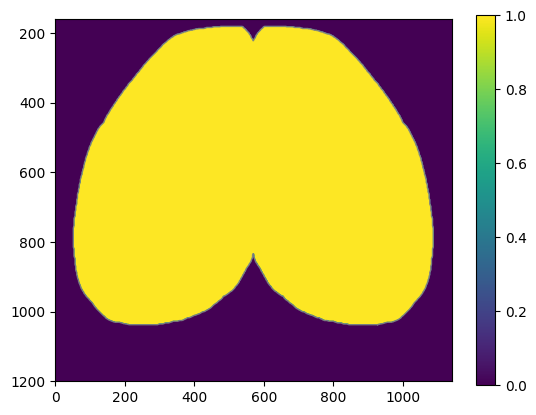

In [53]:
# in addition to the annotation volume, you can get binary masks for individual structures
# in this case, we'll get one for the isocortex
cortex_mask, cm_info = mcc.get_structure_mask(315)

cortex_mask_mip = cortex_mask.max(axis=1)

from skimage import measure
brain_contours = measure.find_contours(cortex_mask_mip>0.5, level=0.5)

    
plt.imshow(cortex_mask_mip)
plt.colorbar()
for contour in brain_contours:
    plt.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=0.9)
# plt.xlim([20,436])
plt.ylim([1200,160])

In [54]:
dict_coord={}
dict_S1_contour = {}
from scipy.ndimage import center_of_mass
for key in S1_experiment_ids:
    dict_coord[key] = center_of_mass(dict_ind[key].max(axis=1))
    S1_contours = measure.find_contours(dict_ind[key].max(axis=1)>0.5, level=0.5)
    dict_S1_contour[key] = S1_contours

In [55]:
from matplotlib.colors import LinearSegmentedColormap

from matplotlib.colors import LinearSegmentedColormap, to_rgb

def make_dynamic_cmap(hex_color, name):
    base_rgb = to_rgb(hex_color)
    
    # Add a middle point (scaled up to boost intensity)
    # boosted = tuple(min(1, c * 2) for c in base_rgb)
    boost = 2
    boosted = tuple(min(1.0, c * boost + 0.2 * (1 - c)) for c in base_rgb)
    return LinearSegmentedColormap.from_list(name, ['black', boosted, 'white'])


cmap_dict = {key: make_dynamic_cmap(color, key) for key, color in palatte_dict.items()}


In [56]:
dict_scaling_factor= {
    "VISrl": 1,
    "SSp-m": 1,
    "SSp-n": 1,
    "SSp-ul": 1,
    "SSp-ll": 1,
    "SSp-bfd": 1
                     }

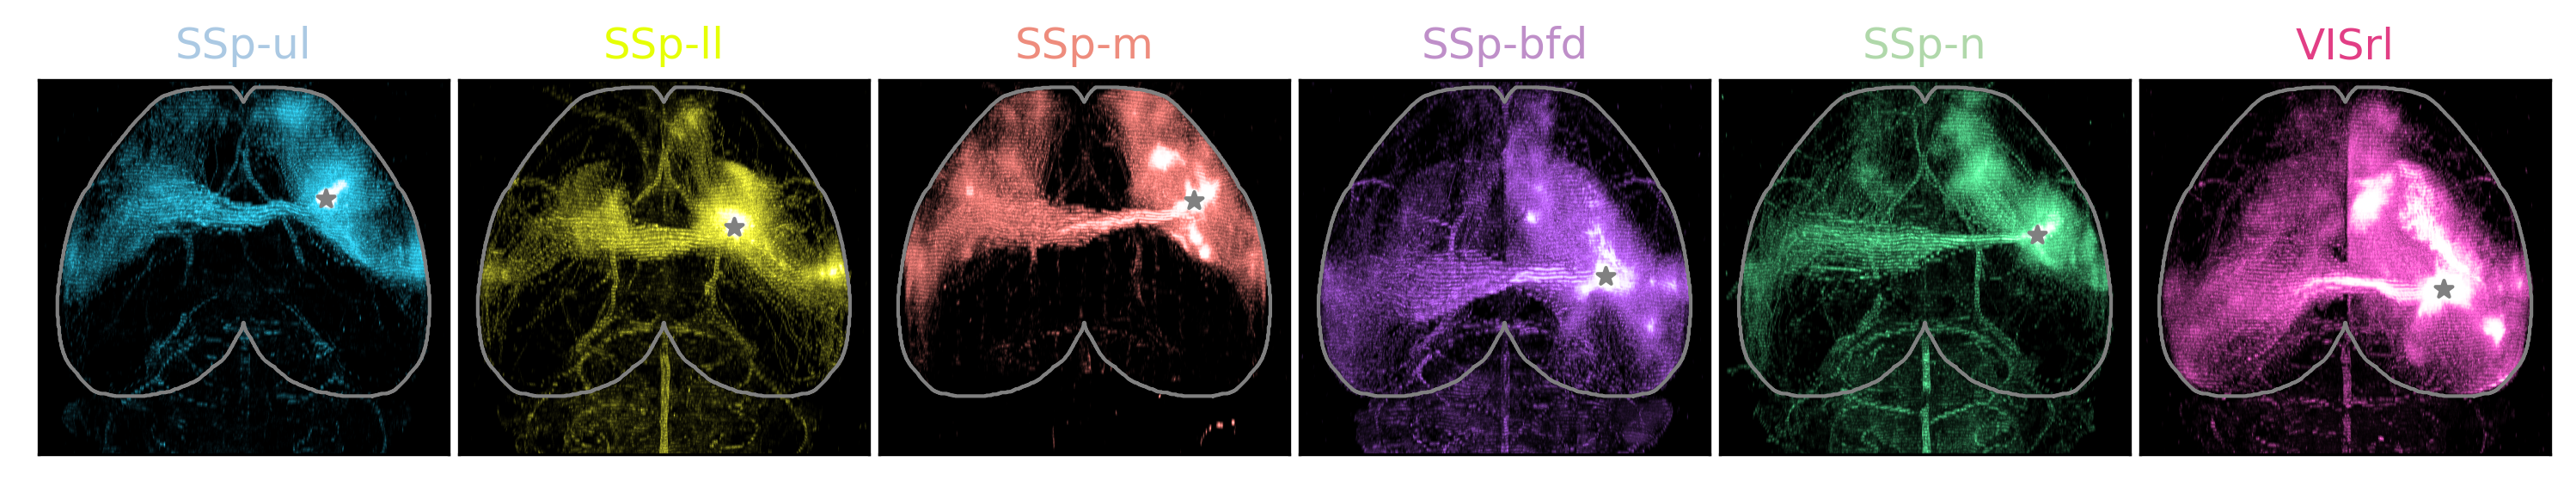

In [59]:
from matplotlib import colors
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)


y_offset = 20;x_offset=20;y_gap=1;x_gap=0;x_width=6

x_start = x_offset
for i_ax in range(6):
    exec("ax{} = fig.add_subplot(gs[y_offset:y_offset+7,x_start:x_start+7])".format(i_ax))
    x_start = x_start+7+x_gap
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    


bdp_short_dict = {'LFP':'SSp-ul','LHP':'SSp-ll','LM':'SSp-m','LW':'SSp-bfd',
                  'LN':'SSp-n','LV':'VISrl'}

dict_bdp_w_order = {'SSp-bfd':0,'SSp-ll':1,'SSp-m':2,'SSp-n':3,'SSp-ul':4,'VISrl':5}

################################################
for i_bdp,bdp in enumerate(['SSp-ul','SSp-ll','SSp-m','SSp-bfd','SSp-n','VISrl']):
    ind_here = dict_bdp_w_order[bdp]
    # pd_mip = arr[:,:,:,ind_here].max(axis=1)
    pd_mip = dict_pd[bdp].max(axis=1)
    
    key = next((k for k, v in bdp_short_dict.items() if v == bdp), None)
    exec("ax{}.imshow(pd_mip*dict_scaling_factor[bdp],cmap=cmap_dict[key.replace('L','R')],vmin=0,vmax=1)".format(i_bdp))
    exec("ax{}.set_title(bdp,color=palatte_dict[key])".format(i_bdp))

    for contour in brain_contours:
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=1)".format(i_bdp))
    exec("ax{}.scatter(dict_coord[bdp][1],dict_coord[bdp][0],marker='*', s=25, c='gray', zorder=2)".format(i_bdp))

        
for i_key in range(6):    
    exec("ax{}.set_ylim([1200,160])".format(i_key))
    
plt.savefig('figS5-Tlx3-cre-S1-seeded-allen-connectivity-atlas-MIP.svg',format='svg',dpi=300)

In [32]:
dict_pd[bdp][:,:700,:].shape

(1320, 800, 1140)

In [176]:
dict_bdps_w_order = {'LW':0,'LV':5,'LN':3,'LM':2,'LHP':1,'LFP':4}


In [35]:
# Precompute MIPs for body parts and store in a dict
precomputed_mips = {}

for label in bdp_w_order:
    i_order = dict_bdps_w_order[label]
    vol_mip = np.mean(cortical_projection[..., i_order], axis=1)  # shape: (1320, 1140)
    precomputed_mips[label] = vol_mip


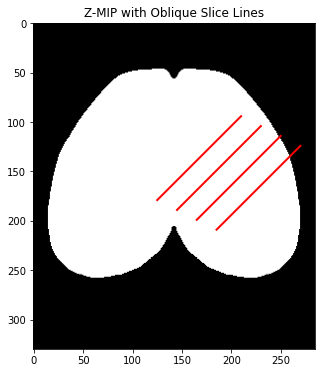

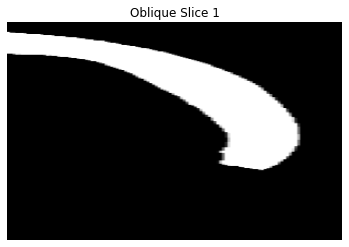

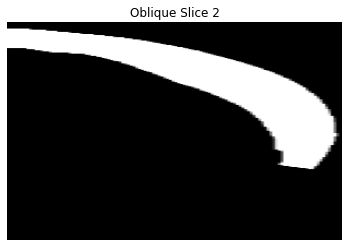

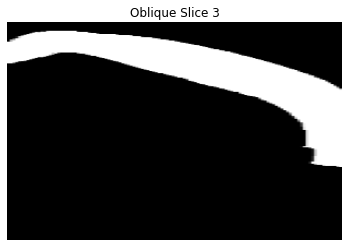

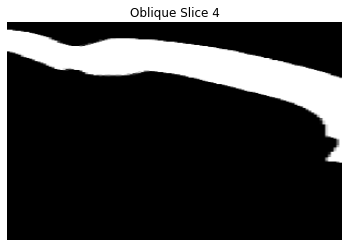

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

# Assume brain_mask_ds is already loaded (y, x, z)
height, width, depth = brain_mask_ds.shape
num_slices = 4
angle_deg = 45
angle_rad = np.deg2rad(angle_deg)

# Oblique plane parameters
plane_width = 120   # width of the oblique slice (in-plane)
plane_height = 200  # height of the oblique slice (in-plane)

# Direction vector for plane (unit vector in x-y)
dx = np.cos(angle_rad)
dy = -np.sin(angle_rad)  # negative slope: y decreases as x increases

# Spacing between planes
slice_spacing = 20
y_base = height - 1 - 120
y_step = 10

# Display MIP + slice lines
plt.figure(figsize=(10, 6))
mip = np.max(brain_mask_ds, axis=2)
plt.imshow(mip, cmap='gray')
plt.title("Z-MIP with Oblique Slice Lines")

oblique_slices = []

for i in range(num_slices):
    # Origin of oblique plane
    x0 = width - (i + 1) * slice_spacing - 80
    y0 = y_base - i * y_step
    z0 = 0  # start from shallow z (can change if needed)

    # Generate grid in the oblique 2D plane
    # u: along the 45° axis (diagonal); v: orthogonal (into depth)
    u = np.linspace(0, plane_width - 1, plane_width)
    v = np.linspace(0, plane_height - 1, plane_height)
    uu, vv = np.meshgrid(u, v)

    # Direction vectors for u and v axes
    u_vec = np.array([dy, dx])            # u: diagonal (y, x)
    v_vec = np.array([0, 0, 1])           # v: depth (z)

    # Build coordinates in 3D space
    x_coords = x0 + uu * dx
    y_coords = y0 + uu * dy
    z_coords = vv + z0

    # Clip coordinates to volume bounds
    x_coords = np.clip(x_coords, 0, width - 1)
    y_coords = np.clip(y_coords, 0, height - 1)
    z_coords = np.clip(z_coords, 0, depth - 1)

    coords = np.vstack([y_coords.ravel(), x_coords.ravel(), z_coords.ravel()])
    sampled = map_coordinates(brain_mask_ds, coords, order=1, mode='nearest')
    slice_img = sampled.reshape(plane_height, plane_width)
    oblique_slices.append(slice_img)

    # Visualize slice line on MIP
    line_x = [x0, x0 + dx * plane_width]
    line_y = [y0, y0 + dy * plane_width]
    plt.plot(line_x, line_y, color='red', linewidth=2)

plt.show()

# Display extracted oblique slices
for i, slice_img in enumerate(oblique_slices):
    plt.figure()
    plt.title(f'Oblique Slice {i+1}')
    plt.imshow(slice_img, cmap='gray', aspect='auto')
    plt.axis('off')


**Compose colors**

In [289]:
dict_scaling_factor= {'LW':2,'LV':1.5,'LN':1,'LM':1,'LFP':1,'LHP':1}
bdp_w_order = ['LV','LW','LN','LM']


In [290]:
import matplotlib.colors as mcolors

# Preprocess: convert hex palette to RGB array
# rgb_palette = {
#     k: np.array(mcolors.to_rgb(v), dtype=np.float32)
#     for k, v in palatte_dict.items()
# }

import colorsys

def boost_color(hex_color, sat_boost=1, light_boost=1):
    """Boosts saturation and lightness of a hex color"""
    rgb = mcolors.to_rgb(hex_color)
    h, l, s = colorsys.rgb_to_hls(*rgb)
    s = min(s * sat_boost, 1.0)
    l = min(l * light_boost, 1.0)
    boosted_rgb = colorsys.hls_to_rgb(h, l, s)
    return np.array(boosted_rgb, dtype=np.float32)

rgb_palette = {
    k: boost_color(v) for k, v in palatte_dict.items()
}


# Start with 80% white base from structural mask
brain_mask_norm = (brain_mask_ds / brain_mask_ds.max()).astype(np.float32)
composite_rgb = np.empty((*brain_mask_ds.shape, 3), dtype=np.float32)
# for c in range(3):
#     composite_rgb[..., c] = brain_mask_norm * 0.8  # white background


# STEP 1: Blend all projections with their unique scaling factor
for label in bdp_w_order:
    # Use label_r for both color and scale for consistency
    label_r = label.replace('L', 'R')
    color = rgb_palette[label_r]
    i_order = dict_bdps_w_order[label]
    scale = dict_scaling_factor.get(label, 1.0) # BUG FIX: Use label_r to get the scale

    vol = proj_channels_ds[..., i_order]  # (Y, Z, X)

    # Blend the scaled volume into the composite image
    for c in range(3):
        composite_rgb[..., c] += vol * color[c] * scale 
        
# STEP 2: Normalize the final result instead of clipping
if composite_rgb.max() > 0:
    composite_rgb /= composite_rgb.max()

# composite_rgb = np.clip(composite_rgb, 0, 1)
# gamma = 0.6  # <1.0 brightens midtones
# composite_rgb = composite_rgb ** gamma

brightness_boost = 1.5  # You can adjust this
composite_rgb *= brightness_boost
composite_rgb = np.clip(composite_rgb, 0, 1)


/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:12: RuntimeWarning: Mean of empty slice
  if sys.path[0] == '':


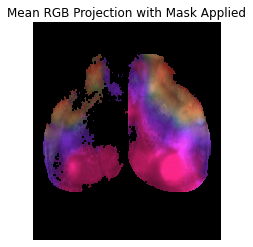

In [291]:
import numpy as np
import matplotlib.pyplot as plt

# Apply mask: compute mean across RGB channels
mask = composite_rgb.mean(axis=-1) < 0.2  # shape (330, 285, 200)

# Broadcast mask to last dimension (RGB)
composite_rgb_masked = composite_rgb.copy()
composite_rgb_masked[mask] = np.nan  # set all channels to nan where mask is True

# Compute nanmean along axis=2 (depth)
composite_rgb_mean = np.nanmean(composite_rgb_masked, axis=2)  # shape (330, 285, 3)

# Plot using imshow
plt.imshow(composite_rgb_mean)
plt.axis('off')
plt.title("Mean RGB Projection with Mask Applied")
plt.show()


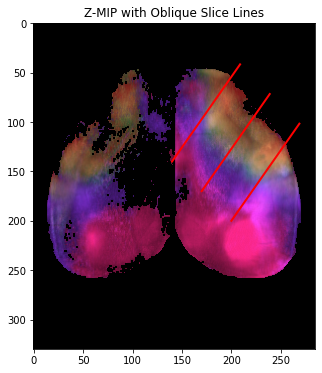

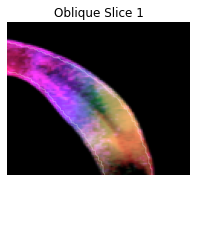

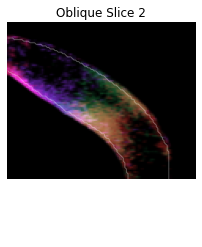

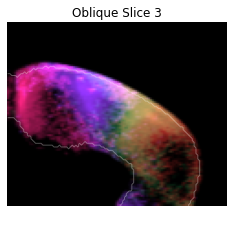

In [292]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

# Assume brain_mask_ds is already loaded (y, x, z)
height, width, depth = brain_mask_ds.shape
num_slices = 3
angle_deg = 55
angle_rad = np.deg2rad(angle_deg)

# Oblique plane parameters
plane_width = 120   # width of the oblique slice (in-plane)
plane_height = 200  # height of the oblique slice (in-plane)

# Direction vector for plane (unit vector in x-y)
dx = np.cos(angle_rad)
dy = -np.sin(angle_rad)  # negative slope: y decreases as x increases

# Spacing between planes
slice_spacing = 20
y_base = height - 1 - 120
y_step = 30
x_step = 30

# Display MIP + slice lines
plt.figure(figsize=(10, 6))
# mip = np.max(proj_channels_ds[...,0], axis=2)
# plt.imshow(mip, cmap='gray')
plt.imshow(composite_rgb_mean)
plt.title("Z-MIP with Oblique Slice Lines")

oblique_slices = []
contours = {}
for i in range(num_slices):
    # Origin of oblique plane
    x0 = 200 - i * x_step
    y0 = 200 - i * y_step
    z0 = 0  # start from shallow z (can change if needed)

    # Generate grid in the oblique 2D plane
    # u: along the 45° axis (diagonal); v: orthogonal (into depth)
    u = np.linspace(0, plane_width - 1, plane_width)
    v = np.linspace(0, plane_height - 1, plane_height)
    uu, vv = np.meshgrid(u, v)

    # Direction vectors for u and v axes
    u_vec = np.array([dy, dx])            # u: diagonal (y, x)
    v_vec = np.array([0, 0, 1])           # v: depth (z)

    # Build coordinates in 3D space
    x_coords = x0 + uu * dx
    y_coords = y0 + uu * dy
    z_coords = vv + z0

    # Clip coordinates to volume bounds
    x_coords = np.clip(x_coords, 0, width - 1)
    y_coords = np.clip(y_coords, 0, height - 1)
    z_coords = np.clip(z_coords, 0, depth - 1)

    # --- START: MODIFIED CODE ---

    # Create the 3D coordinate array (y, x, z)
    coords = np.vstack([y_coords.ravel(), x_coords.ravel(), z_coords.ravel()])
    
    # Sample each color channel independently from the 4D volume
    sampled_channels = []
    for channel_index in range(composite_rgb.shape[3]):
        # Sample from one 3D channel at a time
        sampled_channel = map_coordinates(composite_rgb[..., channel_index], coords, order=1, mode='nearest')
        sampled_channels.append(sampled_channel.reshape(plane_height, plane_width))

    # Stack the sampled channels back into an RGB image (height, width, 3)
    slice_img = np.stack(sampled_channels, axis=-1)
    
    # --- END: MODIFIED CODE ---
    oblique_slices.append(slice_img)

    # Visualize slice line on MIP
    line_x = [x0, x0 + dx * plane_width]
    line_y = [y0, y0 + dy * plane_width]
    plt.plot(line_x, line_y, color='red', linewidth=2)

    
    # add cortical mask
    from skimage import measure

    # Resample mask with same coords
    sampled_mask = map_coordinates(brain_mask_ds.astype(np.float32), coords, order=1, mode='nearest')
    slice_mask = sampled_mask.reshape(plane_height, plane_width)

    # Binary threshold to define the brain region
    binary_mask = slice_mask > 0.5  # or try 0.1 depending on your mask scale

    # Find contours in the 2D slice (returns list of Nx2 arrays)
    contours[i] = measure.find_contours(binary_mask, level=0.5)


plt.show()

# Display extracted oblique slices
for i, slice_img in enumerate(oblique_slices):
    plt.figure()
    plt.title(f'Oblique Slice {i+1}')
    plt.imshow(slice_img[:100,:,:])
    plt.axis('off')
    for contour in contours[i]:
        plt.plot(contour[:, 1], contour[:, 0], color='white', linewidth=1, alpha=0.3)
        


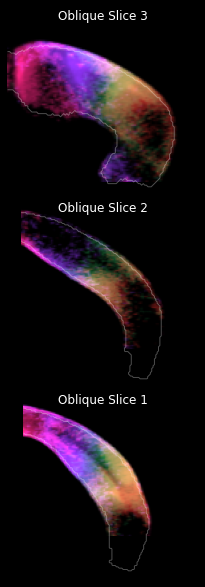

In [299]:
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'

# --- START: MODIFIED CODE ---

# Define the grid layout for the subplots (e.g., 2 rows, 2 columns for 4 slices)
nrows = 3
ncols = 1

# Create a figure and a set of subplots
fig, axes = plt.subplots(nrows, ncols, figsize=(10, 8), facecolor='black')

# Flatten the axes array for easy iteration
axes = axes.flatten()

for i, slice_img in enumerate(oblique_slices):
    # Get the specific subplot axis for the current slice
    ax = axes[2-i]

    ax.set_title(f'Oblique Slice {i+1}', color='white',y=0.9)
    ax.imshow(slice_img[:110,:,:])
    ax.axis('off')

    # Plot contours on the corresponding subplot
    for contour in contours[i]:
        ax.plot(contour[:, 1], contour[:, 0], color='white', linewidth=1, alpha=0.3)

# Hide any unused subplots if the number of slices is less than the grid size
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

# Adjust layout to prevent titles from overlapping
plt.tight_layout(pad=0)

# Save the entire figure with 300 DPI resolution
# bbox_inches='tight' removes extra white space around the figure
plt.savefig('figS5-oblique_slices_comparison.svg', dpi=300, bbox_inches='tight')

# Display the figure
plt.show()

# --- END: MODIFIED CODE ---

In [300]:
dict_scaling_factor= {'LFP':1.2,'LHP':0.7}
bdp_w_order = ['LFP','LHP']


In [301]:
# Start with 80% white base from structural mask
brain_mask_norm = (brain_mask_ds / brain_mask_ds.max()).astype(np.float32)
composite_rgb = np.empty((*brain_mask_ds.shape, 3), dtype=np.float32)
# for c in range(3):
#     composite_rgb[..., c] = brain_mask_norm * 0.8  # white background


# STEP 1: Blend all projections with their unique scaling factor
for label in bdp_w_order:
    # Use label_r for both color and scale for consistency
    label_r = label.replace('L', 'R')
    color = rgb_palette[label_r]
    i_order = dict_bdps_w_order[label]
    scale = dict_scaling_factor.get(label, 1.0) # BUG FIX: Use label_r to get the scale

    vol = proj_channels_ds[..., i_order]  # (Y, Z, X)

    # Blend the scaled volume into the composite image
    for c in range(3):
        composite_rgb[..., c] += vol * color[c] * scale 
        
# STEP 2: Normalize the final result instead of clipping
if composite_rgb.max() > 0:
    composite_rgb /= composite_rgb.max()

# composite_rgb = np.clip(composite_rgb, 0, 1)
# gamma = 0.6  # <1.0 brightens midtones
# composite_rgb = composite_rgb ** gamma

brightness_boost = 1.5  # You can adjust this
composite_rgb *= brightness_boost
composite_rgb = np.clip(composite_rgb, 0, 1)


/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:12: RuntimeWarning: Mean of empty slice
  if sys.path[0] == '':


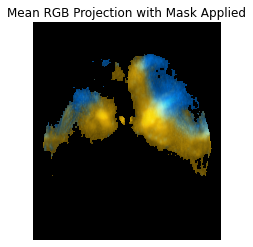

In [302]:
import numpy as np
import matplotlib.pyplot as plt

# Apply mask: compute mean across RGB channels
mask = composite_rgb.mean(axis=-1) < 0.2  # shape (330, 285, 200)

# Broadcast mask to last dimension (RGB)
composite_rgb_masked = composite_rgb.copy()
composite_rgb_masked[mask] = np.nan  # set all channels to nan where mask is True

# Compute nanmean along axis=2 (depth)
composite_rgb_mean = np.nanmean(composite_rgb_masked, axis=2)  # shape (330, 285, 3)

# Plot using imshow
plt.imshow(composite_rgb_mean)
plt.axis('off')
plt.title("Mean RGB Projection with Mask Applied")
plt.show()


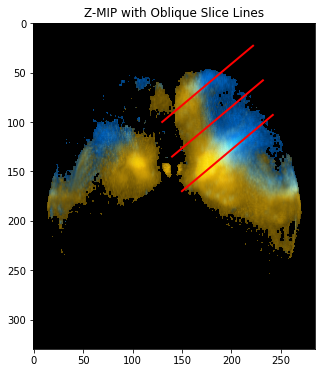

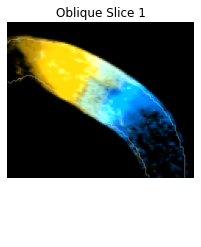

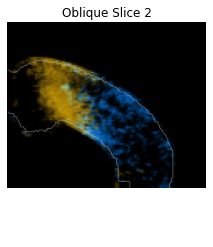

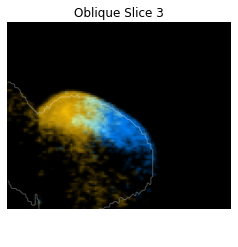

In [303]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

# Assume brain_mask_ds is already loaded (y, x, z)
height, width, depth = brain_mask_ds.shape
num_slices = 3
angle_deg = 40
angle_rad = np.deg2rad(angle_deg)

# Oblique plane parameters
plane_width = 120   # width of the oblique slice (in-plane)
plane_height = 200  # height of the oblique slice (in-plane)

# Direction vector for plane (unit vector in x-y)
dx = np.cos(angle_rad)
dy = -np.sin(angle_rad)  # negative slope: y decreases as x increases

# Spacing between planes
slice_spacing = 20
y_base = height - 1 - 120
y_step = 35
x_step = 10

# Display MIP + slice lines
plt.figure(figsize=(10, 6))
# mip = np.max(proj_channels_ds[...,0], axis=2)
# plt.imshow(mip, cmap='gray')
plt.imshow(composite_rgb_mean)
plt.title("Z-MIP with Oblique Slice Lines")

oblique_slices = []
contours = {}
for i in range(num_slices):
    # Origin of oblique plane
    x0 = 150 - i * x_step
    y0 = 170 - i * y_step
    z0 = 0  # start from shallow z (can change if needed)

    # Generate grid in the oblique 2D plane
    # u: along the 45° axis (diagonal); v: orthogonal (into depth)
    u = np.linspace(0, plane_width - 1, plane_width)
    v = np.linspace(0, plane_height - 1, plane_height)
    uu, vv = np.meshgrid(u, v)

    # Direction vectors for u and v axes
    u_vec = np.array([dy, dx])            # u: diagonal (y, x)
    v_vec = np.array([0, 0, 1])           # v: depth (z)

    # Build coordinates in 3D space
    x_coords = x0 + uu * dx
    y_coords = y0 + uu * dy
    z_coords = vv + z0

    # Clip coordinates to volume bounds
    x_coords = np.clip(x_coords, 0, width - 1)
    y_coords = np.clip(y_coords, 0, height - 1)
    z_coords = np.clip(z_coords, 0, depth - 1)

    # --- START: MODIFIED CODE ---

    # Create the 3D coordinate array (y, x, z)
    coords = np.vstack([y_coords.ravel(), x_coords.ravel(), z_coords.ravel()])
    
    # Sample each color channel independently from the 4D volume
    sampled_channels = []
    for channel_index in range(composite_rgb.shape[3]):
        # Sample from one 3D channel at a time
        sampled_channel = map_coordinates(composite_rgb[..., channel_index], coords, order=1, mode='nearest')
        sampled_channels.append(sampled_channel.reshape(plane_height, plane_width))

    # Stack the sampled channels back into an RGB image (height, width, 3)
    slice_img = np.stack(sampled_channels, axis=-1)
    
    # --- END: MODIFIED CODE ---
    oblique_slices.append(slice_img)

    # Visualize slice line on MIP
    line_x = [x0, x0 + dx * plane_width]
    line_y = [y0, y0 + dy * plane_width]
    plt.plot(line_x, line_y, color='red', linewidth=2)

    
    # add cortical mask
    from skimage import measure

    # Resample mask with same coords
    sampled_mask = map_coordinates(brain_mask_ds.astype(np.float32), coords, order=1, mode='nearest')
    slice_mask = sampled_mask.reshape(plane_height, plane_width)

    # Binary threshold to define the brain region
    binary_mask = slice_mask > 0.5  # or try 0.1 depending on your mask scale

    # Find contours in the 2D slice (returns list of Nx2 arrays)
    contours[i] = measure.find_contours(binary_mask, level=0.5)


plt.show()

# Display extracted oblique slices
for i, slice_img in enumerate(oblique_slices):
    plt.figure()
    plt.title(f'Oblique Slice {i+1}')
    plt.imshow(slice_img[:100,:,:])
    plt.axis('off')
    for contour in contours[i]:
        plt.plot(contour[:, 1], contour[:, 0], color='white', linewidth=1, alpha=0.3)

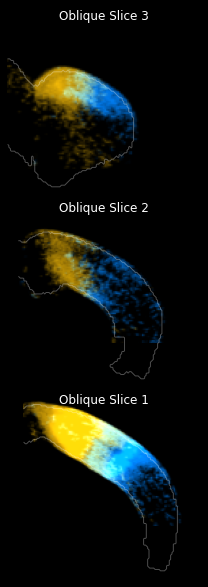

In [304]:



# --- START: MODIFIED CODE ---

# Define the grid layout for the subplots (e.g., 2 rows, 2 columns for 4 slices)
nrows = 3
ncols = 1

# Create a figure and a set of subplots
fig, axes = plt.subplots(nrows, ncols, figsize=(10, 8), facecolor='black')

# Flatten the axes array for easy iteration
axes = axes.flatten()

for i, slice_img in enumerate(oblique_slices):
    # Get the specific subplot axis for the current slice
    ax = axes[2-i]

    ax.set_title(f'Oblique Slice {i+1}', color='white',y=0.9)
    ax.imshow(slice_img[:100,:,:])
    ax.axis('off')

    # Plot contours on the corresponding subplot
    for contour in contours[i]:
        ax.plot(contour[:, 1], contour[:, 0], color='white', linewidth=1, alpha=0.3)

# Hide any unused subplots if the number of slices is less than the grid size
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.rcParams['svg.fonttype'] = 'none'
# Adjust layout to prevent titles from overlapping
plt.tight_layout(pad=0)

# Save the entire figure with 300 DPI resolution
# bbox_inches='tight' removes extra white space around the figure
plt.savefig('figS5-oblique_slices_comparison_FPHP.svg', dpi=300, bbox_inches='tight')

# Display the figure
plt.show()

# --- END: MODIFIED CODE ---




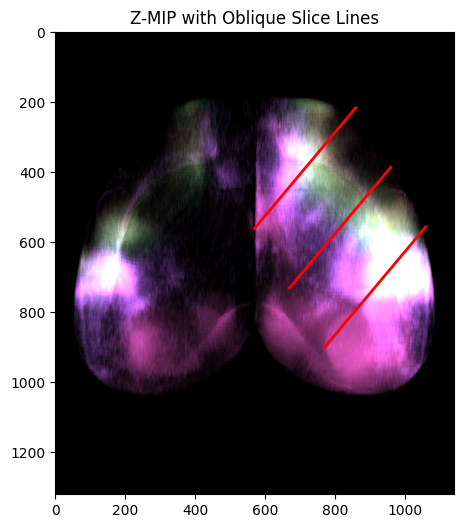

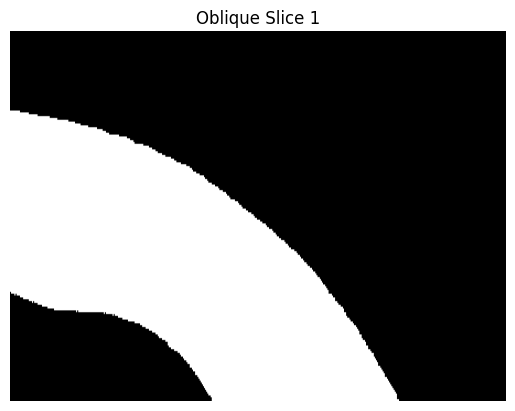

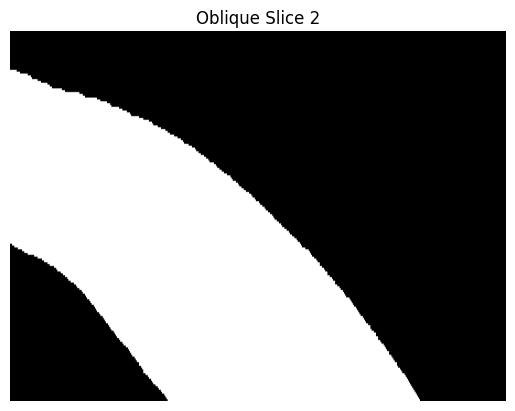

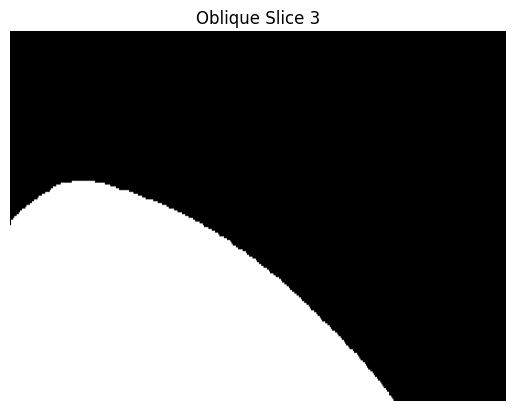

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

brain_mask_ds = cortical_mask.transpose((0,2,1))
# Assume brain_mask_ds is already loaded (y, x, z)
height, width, depth = brain_mask_ds.shape
num_slices = 3
angle_deg = 50
angle_rad = np.deg2rad(angle_deg)

# Oblique plane parameters
plane_width = 450   # width of the oblique slice (in-plane)
plane_height = 200  # height of the oblique slice (in-plane)

# Direction vector for plane (unit vector in x-y)
dx = np.cos(angle_rad)
dy = -np.sin(angle_rad)  # negative slope: y decreases as x increases

# Spacing between planes
slice_spacing = 20
y_base = height - 1 - 120
y_step = 170
x_step = 100

# Display MIP + slice lines
plt.figure(figsize=(10, 6))
# mip = np.max(brain_mask_ds, axis=2)
# plt.imshow(mip, cmap='gray')
plt.imshow(canvas_rgb)
plt.title("Z-MIP with Oblique Slice Lines")

oblique_slices = []

for i in range(num_slices):
    # Origin of oblique plane
    x0 = 770 - i * x_step
    y0 = 900 - i * y_step
    z0 = 0  # start from shallow z (can change if needed)

    # Generate grid in the oblique 2D plane
    # u: along the 45° axis (diagonal); v: orthogonal (into depth)
    u = np.linspace(0, plane_width - 1, plane_width)
    v = np.linspace(0, plane_height - 1, plane_height)
    uu, vv = np.meshgrid(u, v)

    # Direction vectors for u and v axes
    u_vec = np.array([dy, dx])            # u: diagonal (y, x)
    v_vec = np.array([0, 0, 1])           # v: depth (z)

    # Build coordinates in 3D space
    x_coords = x0 + uu * dx
    y_coords = y0 + uu * dy
    z_coords = vv + z0

    # Clip coordinates to volume bounds
    x_coords = np.clip(x_coords, 0, width - 1)
    y_coords = np.clip(y_coords, 0, height - 1)
    z_coords = np.clip(z_coords, 0, depth - 1)

    coords = np.vstack([y_coords.ravel(), x_coords.ravel(), z_coords.ravel()])
    sampled = map_coordinates(brain_mask_ds, coords, order=1, mode='nearest')
    slice_img = sampled.reshape(plane_height, plane_width)
    oblique_slices.append(slice_img)

    # Visualize slice line on MIP
    line_x = [x0, x0 + dx * plane_width]
    line_y = [y0, y0 + dy * plane_width]
    plt.plot(line_x, line_y, color='red', linewidth=2)

plt.show()

# Display extracted oblique slices
for i, slice_img in enumerate(oblique_slices):
    plt.figure()
    plt.title(f'Oblique Slice {i+1}')
    plt.imshow(slice_img, cmap='gray', aspect='auto')
    plt.axis('off')


In [16]:
# ss = cortical_projection.shape
# composite_rgb = np.zeros((ss[0],ss[2],ss[1], 3), dtype=np.float32)


# for label in bdp_w_order:
#     i_order = dict_bdps_w_order[label]
#     vol = cortical_projection[..., i_order].transpose((0,2,1)) 

#     # Normalize (if needed) to [0, 1] — or scale using your dict_scaling_factor
#     vol_scaled = vol / 65536.0

#     # Apply custom colormap to each voxel
#     cmap = cmap_dict[label.replace('L', 'R')]
#     rgba = cmap(vol_scaled)  # shape: (Y, X, Z, 4)
#     rgb = rgba[..., :3] * rgba[..., 3:]  # premultiplied alpha

#     composite_rgb += rgb

In [23]:
brain_mask_ds = cortex_mask.transpose((0,2,1))

In [24]:
import matplotlib.colors as mcolors

# Preprocess: convert hex palette to RGB array
rgb_palette = {
    k: np.array(mcolors.to_rgb(v), dtype=np.float32)
    for k, v in palatte_dict.items()
}

# Start with 80% white base from structural mask
brain_mask_norm = (brain_mask_ds / brain_mask_ds.max()).astype(np.float32)
composite_rgb = np.empty((*brain_mask_ds.shape, 3), dtype=np.float32)
for c in range(3):
    composite_rgb[..., c] = brain_mask_norm * 0.8  # white background

# Blend in each projection
for label in bdp_w_order:
    label_r = label.replace('L', 'R')
    color = rgb_palette[label_r]
    i_order = dict_bdps_w_order[label]
    scale = dict_scaling_factor.get(label_r, 1.0)

    vol = cortical_projection[..., i_order].transpose((0, 2, 1))  # (Y, Z, X)
    vol_scaled = np.clip(vol * scale, 0, 1).astype(np.float32)     # ∈ [0, 1]

    # Blend directly into RGB channels
    for c in range(3):
        composite_rgb[..., c] += vol_scaled * color[c]


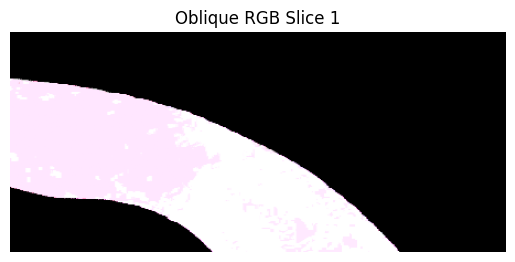

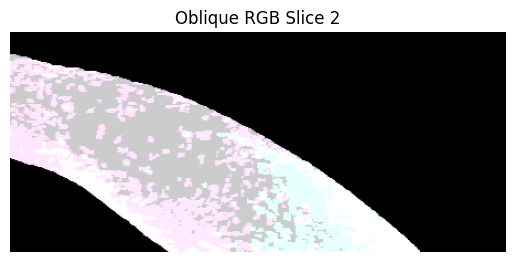

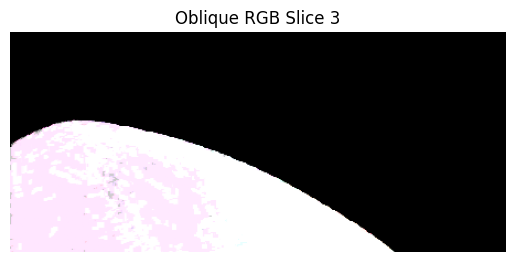

In [30]:
# Assume: composite_rgb.shape = (Y, X, Z, 3)
# composite_rgb = np.stack([channel_r, channel_g, channel_b], axis=-1)  # just placeholder
# composite_rgb = composite_rgb.transpose((0, 2, 1, 3))  # to match brain_mask_ds (Y, X, Z, C)

rgb_oblique_slices = []
num_slices = 3
for i in range(num_slices):
    x0 = 770 - i * x_step
    y0 = 900 - i * y_step
    z0 = 0

    u = np.linspace(0, plane_width - 1, plane_width)
    v = np.linspace(0, plane_height - 1, plane_height)
    uu, vv = np.meshgrid(u, v)

    x_coords = x0 + uu * dx
    y_coords = y0 + uu * dy
    z_coords = vv + z0

    x_coords = np.clip(x_coords, 0, width - 1)
    y_coords = np.clip(y_coords, 0, height - 1)
    z_coords = np.clip(z_coords, 0, depth - 1)

    coords = np.vstack([y_coords.ravel(), x_coords.ravel(), z_coords.ravel()])

    # Slice each color channel
    rgb_slice = []
    for c in range(3):
        channel_data = composite_rgb[..., c]
        sampled = map_coordinates(channel_data, coords, order=1, mode='nearest')
        rgb_slice.append(sampled.reshape(plane_height, plane_width))

    rgb_slice = np.stack(rgb_slice, axis=-1)  # (H, W, 3)
    rgb_oblique_slices.append(np.clip(rgb_slice, 0, 1))  # ensure displayable range

# --- Display the RGB slices
for i, rgb_img in enumerate(rgb_oblique_slices):
    plt.figure()
    plt.title(f'Oblique RGB Slice {i+1}')
    plt.imshow(rgb_img)
    plt.axis('off')







In [17]:
result_path = str(PREPARES / "allen-connectivity-atlas/NEW/wild-type-M2")

need to see coordinates

In [18]:
MOs,info = mcc.get_structure_mask(993)

2025-07-08 13:08:45,285 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://download.alleninstitute.org/informatics-archive/current-release/mouse_ccf/annotation/ccf_2017/structure_masks/structure_masks_10/structure_993.nrrd


In [27]:
results_coord={}
results_coord['HP'] = (290,610)
results_coord['FP'] = (237,700)
results_coord['mouth']=(356, 820)
results_coord['nose']=(360, 740)
results_coord['whisker'] = (394, 656.989247311828)
results_coord['visual'] = (506, 605.939393939394)
bodyparts = results_coord.keys()
bdp_short_dict_2 = {"whisker":'RW', "mouth":'RM', "nose":'RN', "FP":'RFP', "HP":'RHP',
                    "visual":'RV'}

In [43]:
experiment_ids_MOs = {
    "MOs_whisker": 141603190,
    "MOs_FP": 157710335,
    # "MOs_HP": 112952510,
    "MOs_nose": 585025284,
    "MOs_HP": 100141454,

}

In [20]:
# Get ALL experiments as DataFrame
all_experiments = mcc.get_experiments(dataframe=True)
print(f"{len(all_experiments)} total experiments")

2992 total experiments


Found 4 experiments.


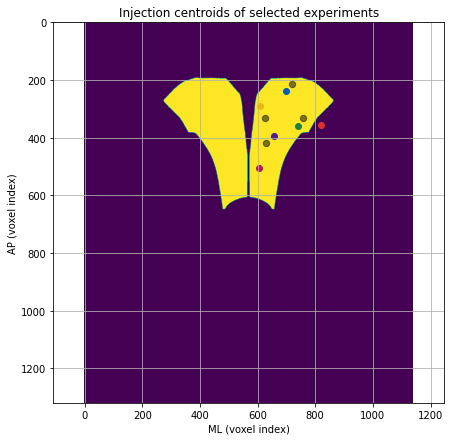

In [44]:
import matplotlib.pyplot as plt

# Your list of experiment IDs
experiment_ids = experiment_ids_MOs.values()

# Filter DataFrame to only these experiments
selected_experiments = all_experiments.loc[experiment_ids]

# Confirm they are all found
print(f"Found {len(selected_experiments)} experiments.")

# Extract coordinates
ap_um = selected_experiments["injection_x"].values
ml_um = selected_experiments["injection_z"].values

# Convert µm to voxel indices in your MIP matrix (voxel size = 10um)
ap_voxels = ap_um / 10
ml_voxels = ml_um / 10

# Plot
plt.figure(figsize=(7,7))

# Optional: background (e.g., MIP of your mask)
# plt.imshow(MIP_surface, cmap="gray", alpha=0.3)
# plt.imshow(results_blob[bdp]==1)
plt.imshow(np.squeeze(np.max(MOs,1)))
plt.scatter(ml_voxels, ap_voxels, c='black', s=40, edgecolors='k',alpha=0.5)
for bdp in bodyparts:
    plt.scatter(results_coord[bdp][1],results_coord[bdp][0],c=palatte_dict[bdp_short_dict_2[bdp]])

# plt.gca().invert_yaxis()  # So anterior is top
plt.xlabel("ML (voxel index)")
plt.ylabel("AP (voxel index)")
plt.title("Injection centroids of selected experiments")
plt.grid(True)
plt.axis("equal")
plt.show()


In [47]:
result_path = str(PREPARES / "allen-connectivity-atlas/NEW/wild-type-M2")
output_dir = result_path
mcc = MouseConnectivityCache(manifest_file=Path(output_dir) / 'manifest.json',resolution=10)

# open up a list of all of the experiments
all_experiments = mcc.get_experiments(dataframe=True)
print("%d total experiments" % len(all_experiments))

2992 total experiments


In [48]:
dict_pd = {}
dict_pd_info = {}
dict_ind = {}
dict_ind_info = {}
for key in experiment_ids_MOs:
    experiment_id = experiment_ids_MOs[key]
    # projection density: number of projecting pixels / voxel volume
    pd, pd_info = mcc.get_projection_density(experiment_id)
    dict_pd[key]=pd
    dict_pd_info[key]=pd_info
    
    # injection density: number of projecting pixels in injection site / voxel volume
    ind, ind_info = mcc.get_injection_density(experiment_id) 
    dict_ind[key] = ind
    dict_ind_info[key] = ind_info
    

2025-07-08 13:58:33,810 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/141603190?image=projection_density&resolution=10
2025-07-08 13:59:45,970 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/141603190?image=injection_density&resolution=10
2025-07-08 14:00:08,839 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/157710335?image=projection_density&resolution=10
2025-07-08 14:01:09,283 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/157710335?image=injection_density&resolution=10
2025-07-08 14:01:31,405 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/585025284?image=projection_density&resolution=10
2025-07-08 14:02:19,250 allensdk.api.api.retrieve_file_ov

In [49]:
for key in dict_pd.keys():
    print(dict_pd[key].shape)

(1320, 800, 1140)
(1320, 800, 1140)
(1320, 800, 1140)
(1320, 800, 1140)


In [50]:
from save_dict_to_hdf5 import *
save_dict_to_hdf5(dict_pd,result_path+'/wild_type_M2.mat')

2992 total experiments


In [52]:
dict_experiment_ids_M2_extra = {
                      'MOs_mouth':166082128, #Rbp4-Cre-113
                      'MOs_visual':158018630 #Gng7-Cre-971
}



In [54]:
result_path = str(PREPARES / "allen-connectivity-atlas/NEW/extra-M2")
output_dir = result_path
mcc = MouseConnectivityCache(manifest_file=Path(output_dir) / 'manifest.json',resolution=10)

# open up a list of all of the experiments
all_experiments = mcc.get_experiments(dataframe=True)
print("%d total experiments" % len(all_experiments))

2992 total experiments


In [55]:
dict_pd = {}
dict_pd_info = {}
dict_ind = {}
dict_ind_info = {}
for key in dict_experiment_ids_M2_extra:
    experiment_id = dict_experiment_ids_M2_extra[key]
    # projection density: number of projecting pixels / voxel volume
    pd, pd_info = mcc.get_projection_density(experiment_id)
    dict_pd[key]=pd
    dict_pd_info[key]=pd_info
    
    # injection density: number of projecting pixels in injection site / voxel volume
    ind, ind_info = mcc.get_injection_density(experiment_id) 
    dict_ind[key] = ind
    dict_ind_info[key] = ind_info
    

2025-07-08 14:27:17,816 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/166082128?image=projection_density&resolution=10
2025-07-08 14:28:20,212 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/166082128?image=injection_density&resolution=10
2025-07-08 14:28:41,194 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/158018630?image=projection_density&resolution=10
2025-07-08 14:29:27,507 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/158018630?image=injection_density&resolution=10


In [56]:
from save_dict_to_hdf5 import *
save_dict_to_hdf5(dict_pd,result_path+'/other_types_M2.mat')

In [58]:
import scipy
scipy.io.savemat('other_types_M2.mat', dict_pd, format='7.3')

ValueError: Format should be '4' or '5'

(1200.0, 180.0)

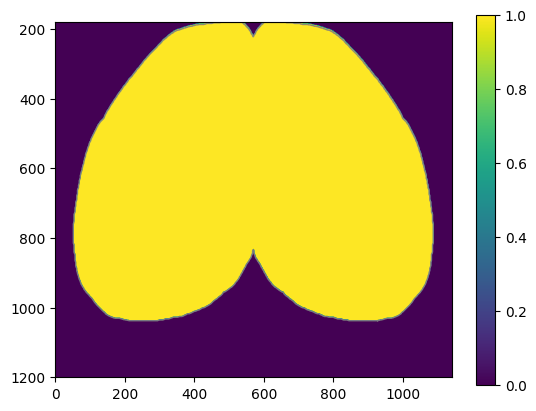

In [26]:
# in addition to the annotation volume, you can get binary masks for individual structures
# in this case, we'll get one for the isocortex
cortex_mask, cm_info = mcc.get_structure_mask(315)

cortex_mask_mip = cortex_mask.max(axis=1)

from skimage import measure
brain_contours = measure.find_contours(cortex_mask_mip>0.5, level=0.5)

    
plt.imshow(cortex_mask_mip)
plt.colorbar()
for contour in brain_contours:
    plt.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=0.9)
# plt.xlim([20,436])
plt.ylim([1200,160])

In [14]:
cortex_mask_mip.shape

(1320, 1140)

In [15]:
dict_coord={}
dict_S1_contour = {}
from scipy.ndimage import center_of_mass
for key in dict_experiment_id:
    dict_coord[key] = center_of_mass(dict_ind[key].max(axis=1))
    S1_contours = measure.find_contours(dict_ind[key].max(axis=1)>0.5, level=0.5)
    dict_S1_contour[key] = S1_contours

In [17]:
from matplotlib.colors import LinearSegmentedColormap
# def make_custom_cmap(hex_color, name):
#     return LinearSegmentedColormap.from_list(name, ['black', hex_color])


from matplotlib.colors import LinearSegmentedColormap, to_rgb

def make_dynamic_cmap(hex_color, name):
    base_rgb = to_rgb(hex_color)
    
    # Add a middle point (scaled up to boost intensity)
    # boosted = tuple(min(1, c * 2) for c in base_rgb)
    boost = 2
    boosted = tuple(min(1.0, c * boost + 0.2 * (1 - c)) for c in base_rgb)
    return LinearSegmentedColormap.from_list(name, ['black', boosted, 'white'])



cmap_dict = {key: make_dynamic_cmap(color, key) for key, color in palatte_dict.items()}


In [23]:
dict_scaling_factor= {'LW':0.7,
                'LV':0.7,
                     'LN':0.5,
                     'LM':0.6,
                     'LFP':0.8,
                     'LHP':0.65}

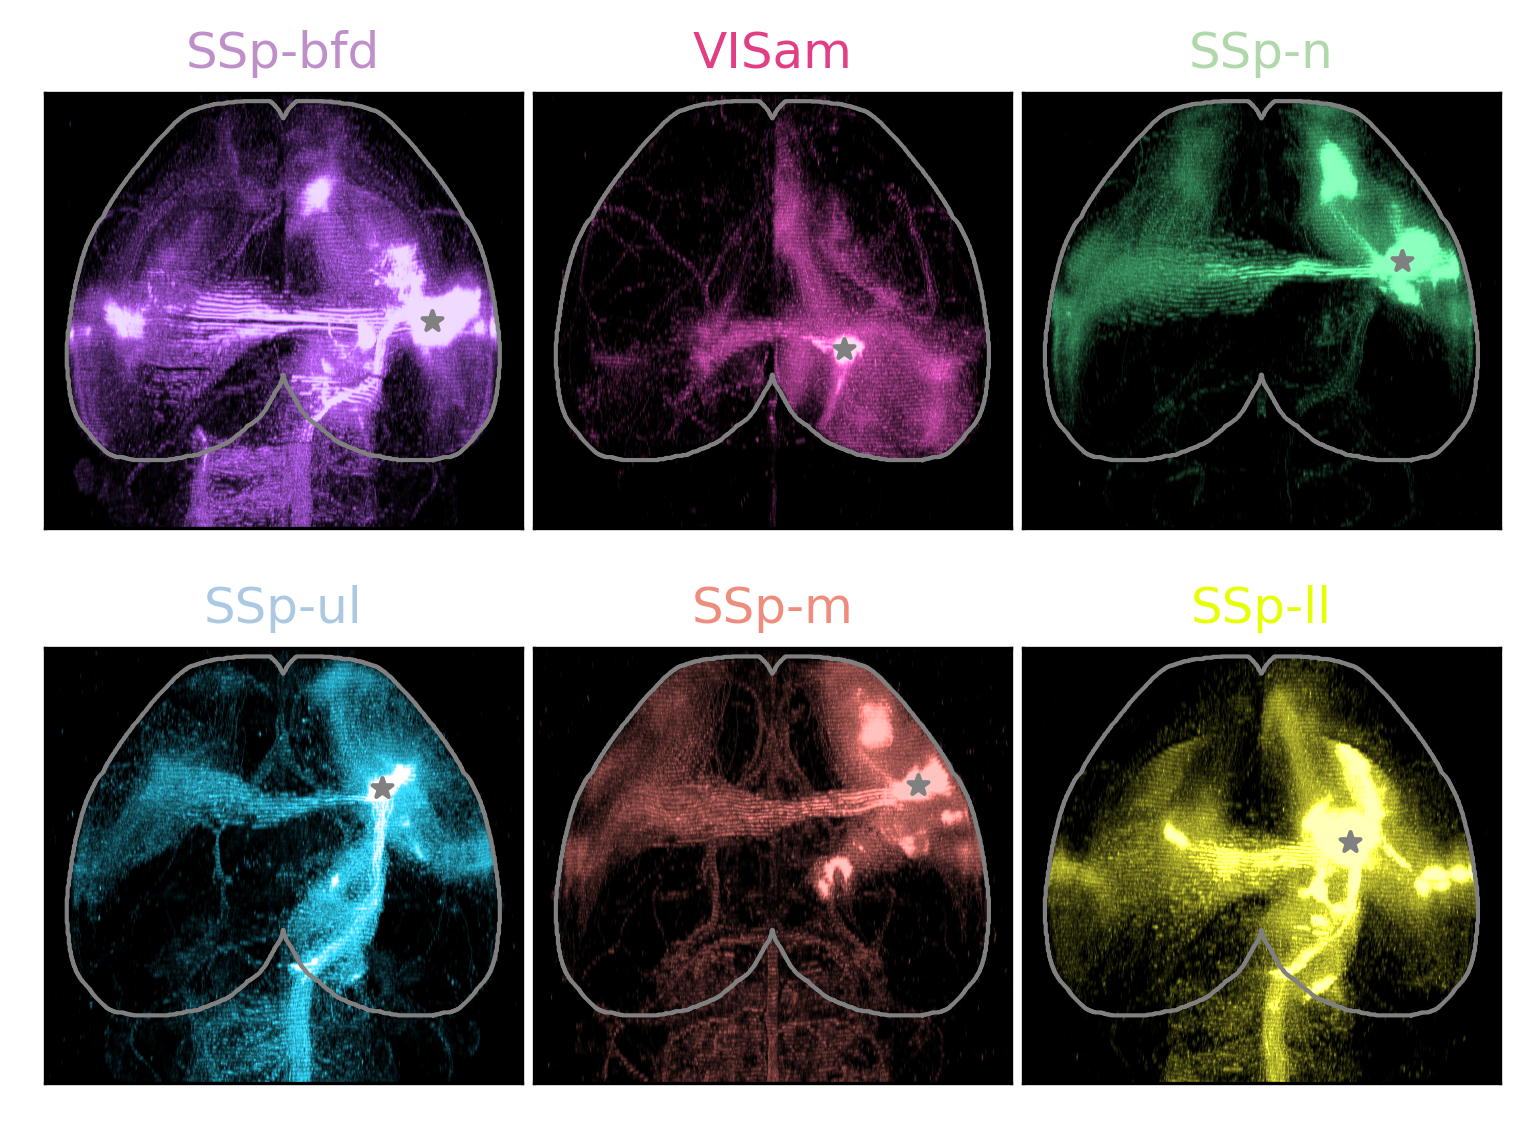

In [27]:
from matplotlib import colors
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)


y_offset = 20;x_offset=20;y_gap=1;x_gap=0;x_width=6

x_start = x_offset
for i_ax in range(3):
    exec("ax{} = fig.add_subplot(gs[y_offset:y_offset+7,x_start:x_start+7])".format(i_ax))
    x_start = x_start+7+x_gap
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
x_start = x_offset
for i_ax in range(3,6):
    exec("ax{} = fig.add_subplot(gs[y_offset+8:y_offset+15,x_start:x_start+7])".format(i_ax))
    x_start = x_start+7+x_gap
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))    
    


bdp_short_dict = {'LFP':'SSp-ul','LHP':'SSp-ll','LM':'SSp-m','LW':'SSp-bfd',
                  'LN':'SSp-n','LV':'VISam'}



################################################
for i_key,key in enumerate(dict_experiment_id):
    pd_mip = dict_pd[key].max(axis=1)
    exec("ax{}.imshow(pd_mip*dict_scaling_factor[key],cmap=cmap_dict[key.replace('L','R')],vmin=0,vmax=0.8)".format(i_key))
    exec("ax{}.set_title(bdp_short_dict[key],color=palatte_dict[key])".format(i_key))
    # exec("ax{}.colorbar()".format(i_key))
    for contour in brain_contours:
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=1)".format(i_key))
    exec("ax{}.scatter(dict_coord[key][1],dict_coord[key][0],marker='*', s=25, c='gray', zorder=2)".format(i_key))

        
for i_key in range(6):    
    exec("ax{}.set_ylim([1200,160])".format(i_key))
    
plt.savefig('figS5-M2-S1-allen-connectivity-atlas-MIP.svg',format='svg',dpi=300)

In [45]:
dict_pd['brain_mask'] = cortex_mask

In [ ]:
with h5py.File("dict_pd.h5", "w") as h5f:
    for key, array in dict_pd.items():
        h5f.create_dataset(key, data=array)  # no compression
